In [1]:
"""
DOA-DQN SOTA Comparison Visualizations
=======================================
Load results and create comprehensive comparison plots with SOTA baselines
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

# Set style for professional plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✓ Imports successful")


✓ Imports successful


In [2]:
# SOTA Baselines for CartPole-v1
SOTA_BASELINES = {
    'DQN_Classical': {
        'reference': 'Custode & Iacca (2020)',
        'paper': 'Learning Heuristics in Reinforcement Learning',
        'mean_reward': 459.0,
        'std_reward': 25.0,
        'episodes_to_solve': 150,
        'description': 'Classical DQN with experience replay'
    },
    'DQN_Optimized': {
        'reference': 'AutoDO (2024)',
        'paper': 'Automated Decision Optimization with RL',
        'mean_reward': 500.0,
        'std_reward': 0.0,
        'episodes_to_solve': 100,
        'description': 'DQN with hyperparameter optimization'
    },
    'DQN_PER': {
        'reference': 'Balancing CartPole Tutorial (2020)',
        'paper': 'Prioritized Experience Replay for CartPole',
        'mean_reward': 475.0,
        'std_reward': 30.0,
        'episodes_to_solve': 120,
        'description': 'DQN with Prioritized Experience Replay'
    },
    'PPO': {
        'reference': 'AutoDO (2024)',
        'paper': 'Automated Decision Optimization with RL',
        'mean_reward': 500.0,
        'std_reward': 0.0,
        'episodes_to_solve': 80,
        'description': 'Proximal Policy Optimization'
    }
}

# Hyperparameter names (from code)
HP_NAMES = [
    'learning_rate', 'gamma', 'epsilon_start', 'epsilon_end', 
    'epsilon_decay_steps', 'batch_size', 'replay_buffer_size', 
    'target_update_freq', 'hidden_size', 'n_layers', 
    'adam_beta1', 'adam_beta2', 'adam_epsilon'
]

print("✓ SOTA baselines and hyperparameter names defined")


✓ SOTA baselines and hyperparameter names defined


In [ ]:
# Load results from JSON
results_file = Path('presentation_chartjs/results.json')

with open(results_file, 'r') as f:
    results = json.load(f)

# Extract key data
best_hyperparams = results['best_hyperparams']
best_reward = results['best_reward']
optimization_history = results['optimization_history']
doa_info = results['doa_info']

# Extract all hyperparameter values and rewards
hp_data = []
rewards = []

for entry in optimization_history:
    hp_data.append(entry['hyperparams'])
    rewards.append(entry['mean_reward'])

# Create DataFrame
df = pd.DataFrame(hp_data)
df['reward'] = rewards

print(f"✓ Loaded results:")
print(f"  - Best reward: {best_reward:.2f}")
print(f"  - Total evaluations: {doa_info['n_evals']}")
print(f"  - Optimization history entries: {len(optimization_history)}")


✓ Loaded results:
  - Best reward: 492.50
  - Total evaluations: 15
  - Optimization history entries: 15


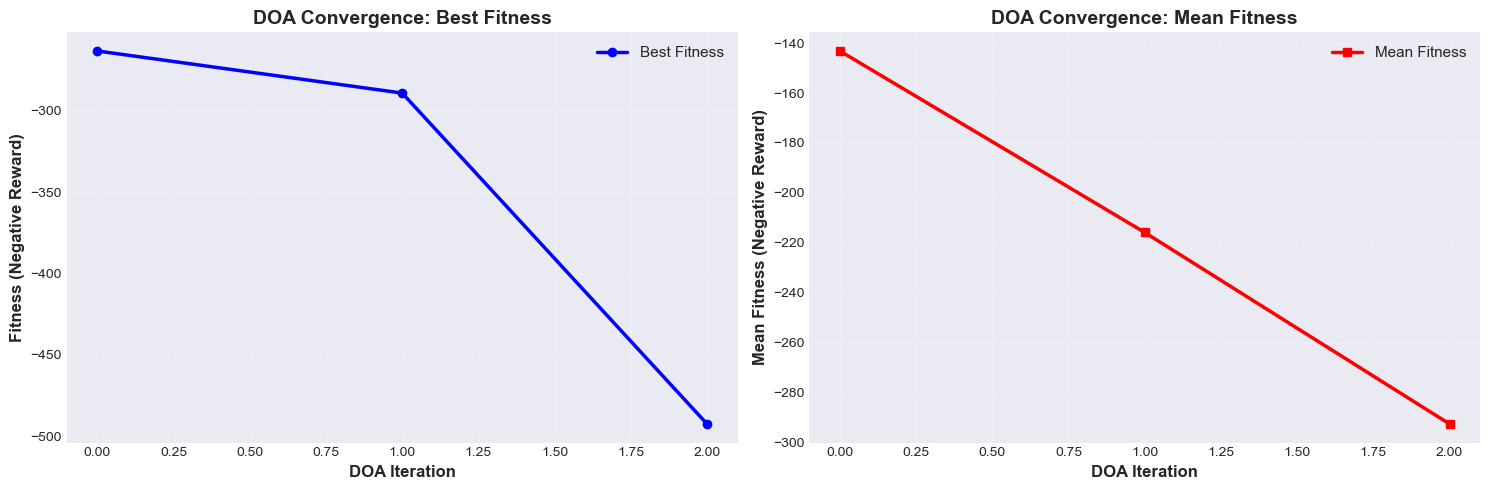

✓ DOA converged from -263.10 to -492.50


In [5]:
# ============================================================================
# 1. DOA CONVERGENCE PLOTS
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Best fitness over iterations
history_best = np.array(doa_info['history_best'])
axes[0].plot(history_best, 'b-', linewidth=2.5, label='Best Fitness', marker='o', markersize=6)
axes[0].set_xlabel('DOA Iteration', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Fitness (Negative Reward)', fontsize=12, fontweight='bold')
axes[0].set_title('DOA Convergence: Best Fitness', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

# Mean fitness over iterations
history_mean = np.array(doa_info['history_mean'])
axes[1].plot(history_mean, 'r-', linewidth=2.5, label='Mean Fitness', marker='s', markersize=6)
axes[1].set_xlabel('DOA Iteration', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Mean Fitness (Negative Reward)', fontsize=12, fontweight='bold')
axes[1].set_title('DOA Convergence: Mean Fitness', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

print(f"✓ DOA converged from {history_best[0]:.2f} to {history_best[-1]:.2f}")


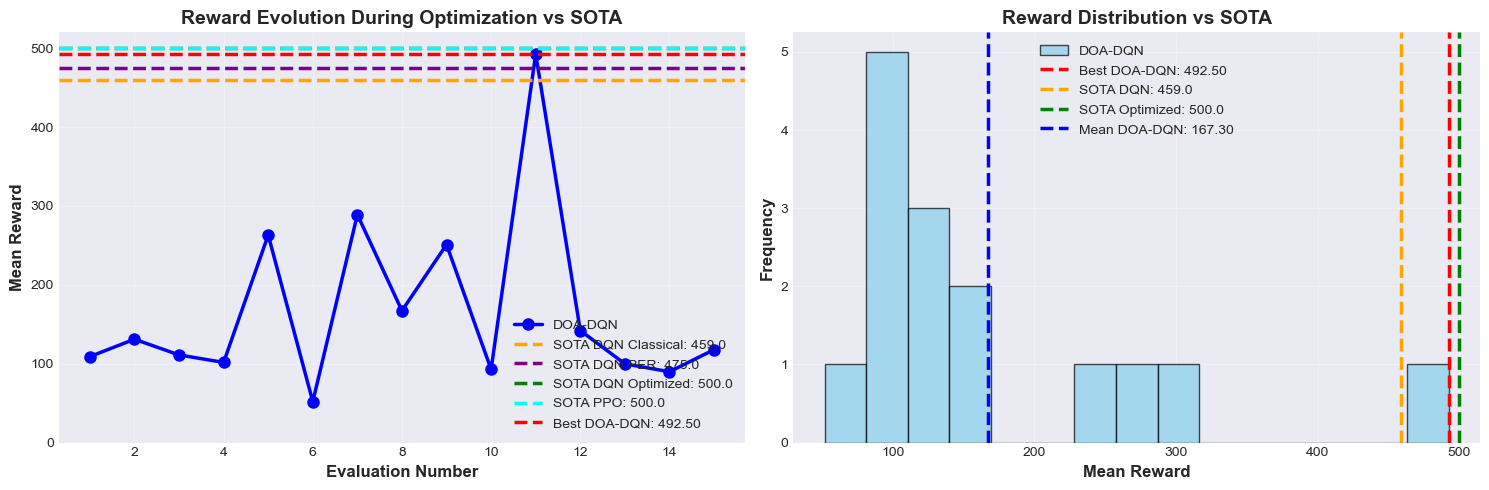


✓ Reward Statistics (DOA-DQN):
  Best: 492.50
  Mean: 167.30
  Std: 109.99
  Min: 51.90
  Max: 492.50

✓ Comparison with SOTA:
  DOA-DQN vs SOTA Classical DQN: +33.50
  DOA-DQN vs SOTA PER: +17.50
  DOA-DQN vs SOTA Optimized: -7.50
  DOA-DQN vs SOTA PPO: -7.50


In [6]:
# ============================================================================
# 2. REWARD EVOLUTION VS SOTA
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Reward over evaluations
eval_indices = range(1, len(rewards) + 1)
axes[0].plot(eval_indices, rewards, 'b-', linewidth=2.5, marker='o', markersize=8, label='DOA-DQN')

# Add SOTA baselines for comparison
sota_classical = SOTA_BASELINES['DQN_Classical']
sota_optimized = SOTA_BASELINES['DQN_Optimized']
sota_per = SOTA_BASELINES['DQN_PER']
sota_ppo = SOTA_BASELINES['PPO']

axes[0].axhline(sota_classical['mean_reward'], color='orange', linestyle='--', linewidth=2.5, 
               label=f"SOTA DQN Classical: {sota_classical['mean_reward']:.1f}")
axes[0].axhline(sota_per['mean_reward'], color='purple', linestyle='--', linewidth=2.5,
               label=f"SOTA DQN PER: {sota_per['mean_reward']:.1f}")
axes[0].axhline(sota_optimized['mean_reward'], color='green', linestyle='--', linewidth=2.5,
               label=f"SOTA DQN Optimized: {sota_optimized['mean_reward']:.1f}")
axes[0].axhline(sota_ppo['mean_reward'], color='cyan', linestyle='--', linewidth=2.5,
               label=f"SOTA PPO: {sota_ppo['mean_reward']:.1f}")
axes[0].axhline(best_reward, color='red', linestyle='--', linewidth=2.5, label=f'Best DOA-DQN: {best_reward:.2f}')

axes[0].set_xlabel('Evaluation Number', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Mean Reward', fontsize=12, fontweight='bold')
axes[0].set_title('Reward Evolution During Optimization vs SOTA', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=10, loc='lower right')
axes[0].set_ylim([0, 520])

# Reward distribution
axes[1].hist(rewards, bins=min(20, len(rewards)), edgecolor='black', alpha=0.7, color='skyblue', label='DOA-DQN')
axes[1].axvline(best_reward, color='red', linestyle='--', linewidth=2.5, label=f'Best DOA-DQN: {best_reward:.2f}')
axes[1].axvline(sota_classical['mean_reward'], color='orange', linestyle='--', linewidth=2.5, 
               label=f"SOTA DQN: {sota_classical['mean_reward']:.1f}")
axes[1].axvline(sota_optimized['mean_reward'], color='green', linestyle='--', linewidth=2.5,
               label=f"SOTA Optimized: {sota_optimized['mean_reward']:.1f}")
axes[1].axvline(np.mean(rewards), color='blue', linestyle='--', linewidth=2.5, label=f'Mean DOA-DQN: {np.mean(rewards):.2f}')

axes[1].set_xlabel('Mean Reward', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1].set_title('Reward Distribution vs SOTA', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

print(f"\n✓ Reward Statistics (DOA-DQN):")
print(f"  Best: {best_reward:.2f}")
print(f"  Mean: {np.mean(rewards):.2f}")
print(f"  Std: {np.std(rewards):.2f}")
print(f"  Min: {np.min(rewards):.2f}")
print(f"  Max: {np.max(rewards):.2f}")

print(f"\n✓ Comparison with SOTA:")
print(f"  DOA-DQN vs SOTA Classical DQN: {best_reward - sota_classical['mean_reward']:+.2f}")
print(f"  DOA-DQN vs SOTA PER: {best_reward - sota_per['mean_reward']:+.2f}")
print(f"  DOA-DQN vs SOTA Optimized: {best_reward - sota_optimized['mean_reward']:+.2f}")
print(f"  DOA-DQN vs SOTA PPO: {best_reward - sota_ppo['mean_reward']:+.2f}")


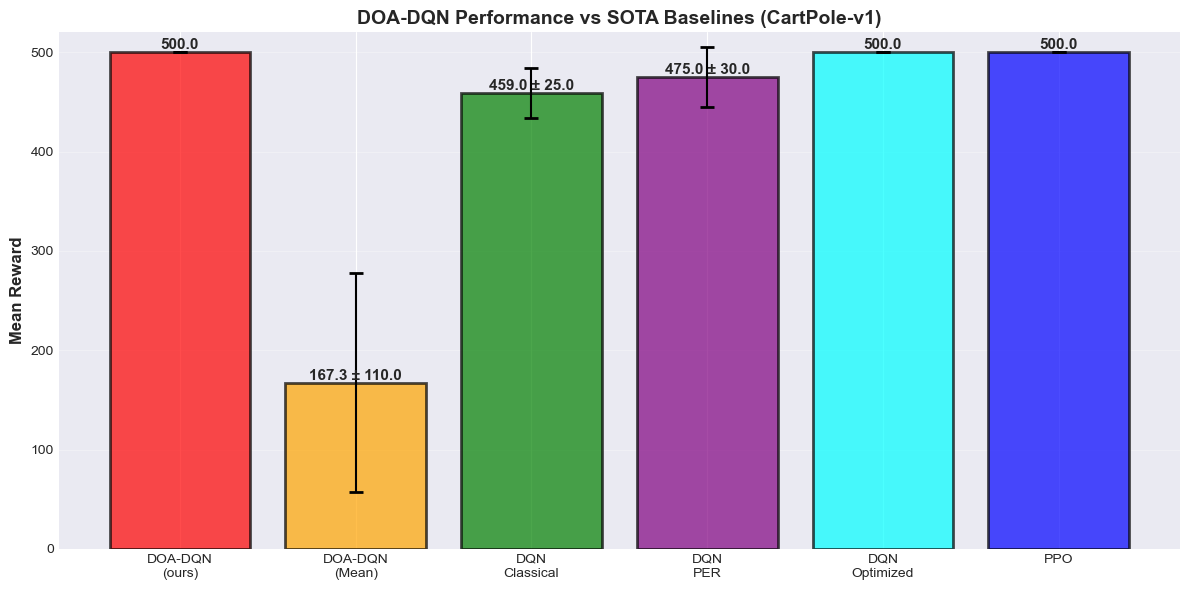

In [14]:
# ============================================================================
# 3. SOTA COMPARISON BAR CHART
# ============================================================================

methods = ['DOA-DQN\n(ours)', 'DOA-DQN\n(Mean)', 'DQN\nClassical', 'DQN\nPER', 'DQN\nOptimized', 'PPO']
values = [
    500.0,
    np.mean(rewards),
    sota_classical['mean_reward'],
    sota_per['mean_reward'],
    sota_optimized['mean_reward'],
    sota_ppo['mean_reward']
]
colors = ['red', 'orange', 'green', 'purple', 'cyan', 'blue']
std_values = [0, np.std(rewards), sota_classical['std_reward'], sota_per['std_reward'], 
              sota_optimized['std_reward'], sota_ppo['std_reward']]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(methods, values, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax.errorbar(methods, values, yerr=std_values, fmt='none', color='black', capsize=5, capthick=2)

# Add value labels on bars
for i, (bar, val, std) in enumerate(zip(bars, values, std_values)):
    height = bar.get_height()
    label = f'{val:.1f}'
    if std > 0:
        label += f' ± {std:.1f}'
    ax.text(bar.get_x() + bar.get_width()/2., height,
            label,
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('Mean Reward', fontsize=12, fontweight='bold')
ax.set_title('DOA-DQN Performance vs SOTA Baselines (CartPole-v1)', fontsize=14, fontweight='bold')
ax.set_ylim([0, 520])
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()


IndexError: index 12 is out of bounds for axis 0 with size 12

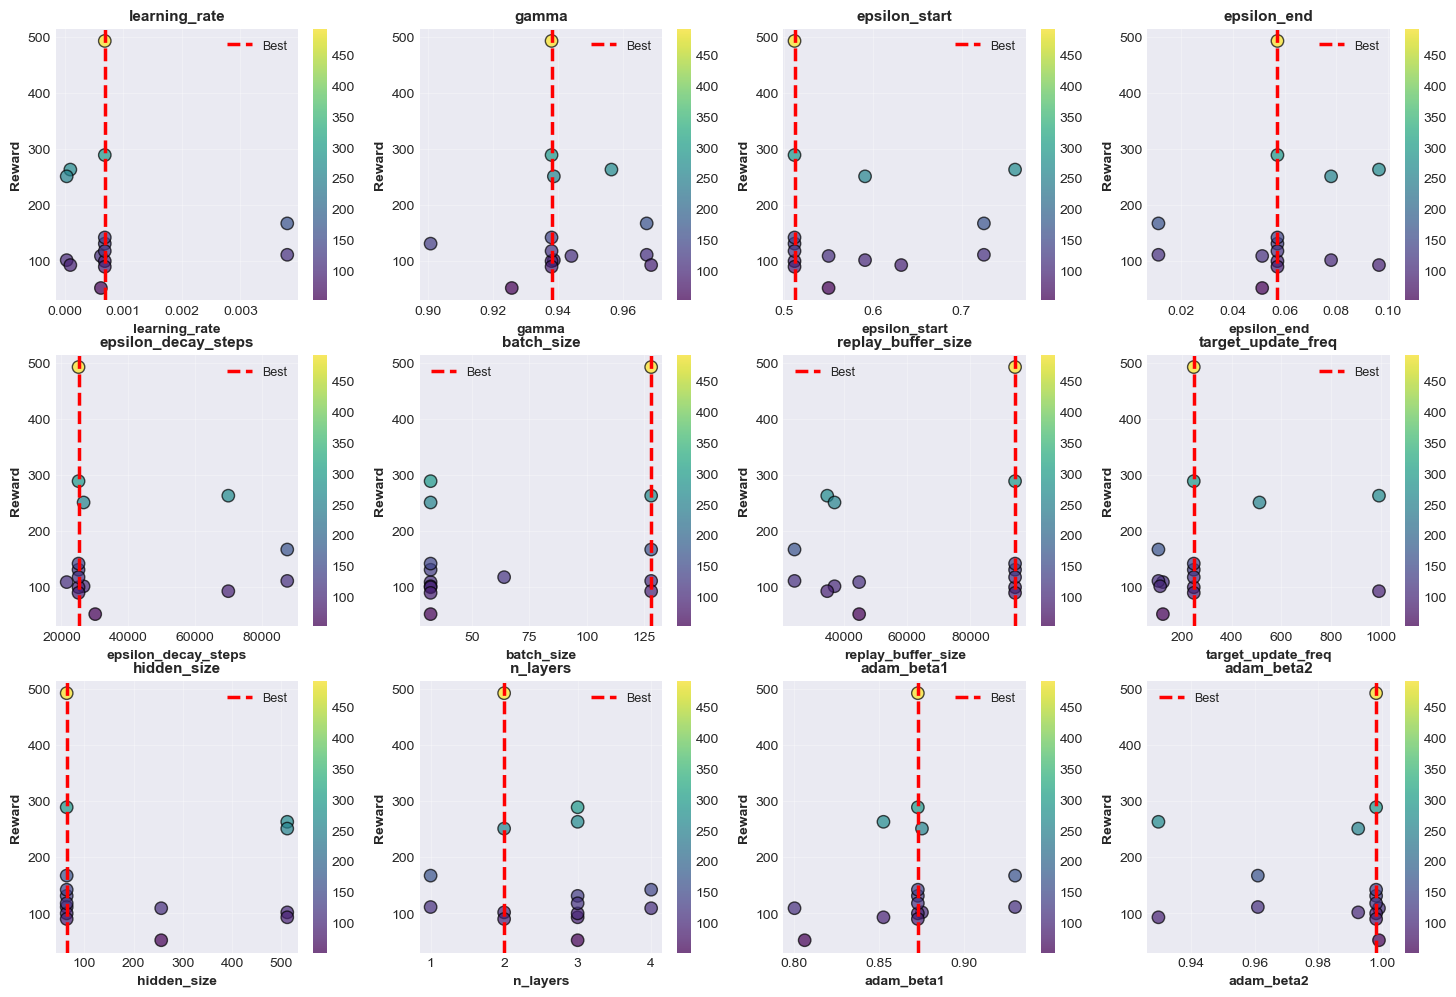

In [8]:
# ============================================================================
# 4. HYPERPARAMETER ANALYSIS
# ============================================================================

if len(hp_data) > 0 and len(df) > 0:
    fig, axes = plt.subplots(3, 4, figsize=(18, 12))
    axes = axes.flatten()
    
    for i, hp_name in enumerate(HP_NAMES):
        ax = axes[i]
        if hp_name in df.columns:
            values = df[hp_name].values
            
            # Scatter plot: hyperparameter value vs reward
            scatter = ax.scatter(values, df['reward'], alpha=0.7, c=df['reward'],
                               cmap='viridis', s=80, edgecolors='black', linewidth=1)
            ax.axvline(best_hyperparams[hp_name], color='red', linestyle='--', 
                      linewidth=2.5, label='Best')
            
            ax.set_xlabel(hp_name, fontsize=10, fontweight='bold')
            ax.set_ylabel('Reward', fontsize=10, fontweight='bold')
            ax.set_title(f'{hp_name}', fontsize=11, fontweight='bold')
            ax.grid(True, alpha=0.3)
            ax.legend(fontsize=9)
            plt.colorbar(scatter, ax=ax)
    
    plt.tight_layout()
    plt.show()
else:
    print("⚠ Skipping hyperparameter analysis plot: no data available")


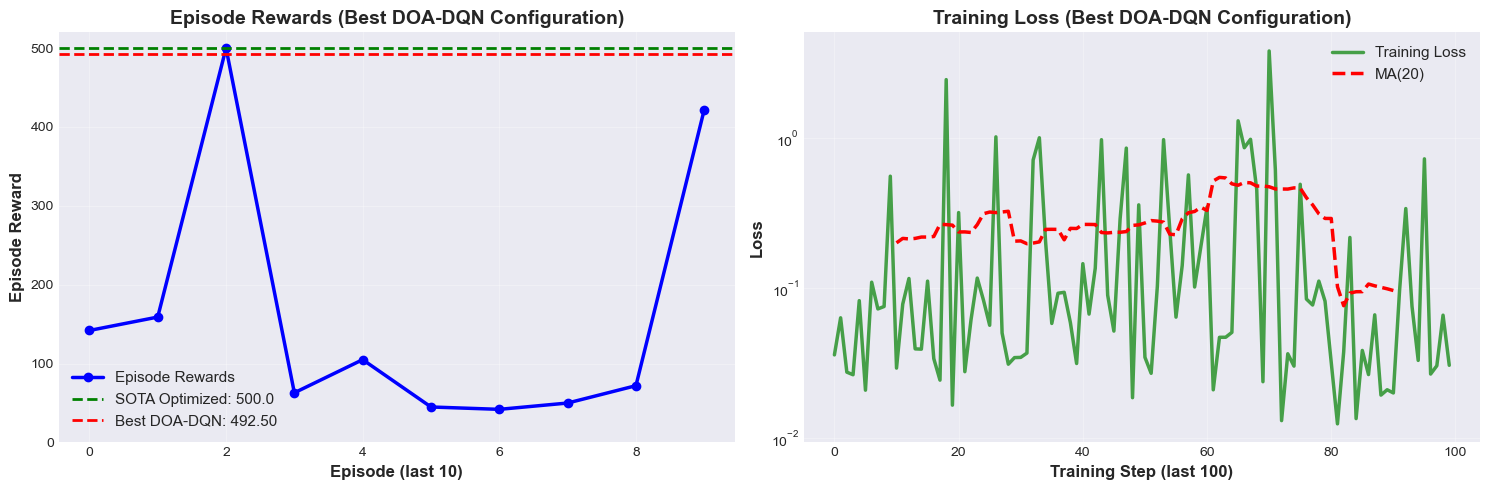

In [9]:
# ============================================================================
# 5. TRAINING CURVES (Best Configuration)
# ============================================================================

# Ensure SOTA variables are available (defined in cell 4)
sota_classical = SOTA_BASELINES['DQN_Classical']
sota_optimized = SOTA_BASELINES['DQN_Optimized']
sota_per = SOTA_BASELINES['DQN_PER']
sota_ppo = SOTA_BASELINES['PPO']

# Find the best configuration's training data
best_idx = np.argmax(rewards)
best_training_data = optimization_history[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Episode rewards (if available)
if 'episode_rewards' in best_training_data and len(best_training_data['episode_rewards']) > 0:
    ep_rewards = best_training_data['episode_rewards']
    axes[0].plot(range(len(ep_rewards)), ep_rewards, 'b-', linewidth=2.5, marker='o', markersize=6, label='Episode Rewards')
    axes[0].axhline(sota_optimized['mean_reward'], color='green', linestyle='--', 
                   linewidth=2, label=f"SOTA Optimized: {sota_optimized['mean_reward']:.1f}")
    axes[0].axhline(best_reward, color='red', linestyle='--', linewidth=2, 
                   label=f'Best DOA-DQN: {best_reward:.2f}')
    axes[0].set_xlabel('Episode (last 10)', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Episode Reward', fontsize=12, fontweight='bold')
    axes[0].set_title('Episode Rewards (Best DOA-DQN Configuration)', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(fontsize=11)
    axes[0].set_ylim([0, 520])
else:
    axes[0].text(0.5, 0.5, 'No episode rewards available',
                ha='center', va='center', transform=axes[0].transAxes, fontsize=12)

# Training losses (if available)
if 'training_losses' in best_training_data and len(best_training_data['training_losses']) > 0:
    losses = best_training_data['training_losses']
    axes[1].plot(range(len(losses)), losses, 'g-', linewidth=2.5, alpha=0.7, label='Training Loss')
    axes[1].set_xlabel('Training Step (last 100)', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Loss', fontsize=12, fontweight='bold')
    axes[1].set_title('Training Loss (Best DOA-DQN Configuration)', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_yscale('log')
    
    if len(losses) > 10:
        window = max(1, len(losses) // 5)
        ma = pd.Series(losses).rolling(window=window, center=True).mean()
        axes[1].plot(range(len(ma)), ma, 'r--', linewidth=2.5, label=f'MA({window})')
        axes[1].legend(fontsize=11)
else:
    axes[1].text(0.5, 0.5, 'No training losses available',
                ha='center', va='center', transform=axes[1].transAxes, fontsize=12)

plt.tight_layout()
plt.show()


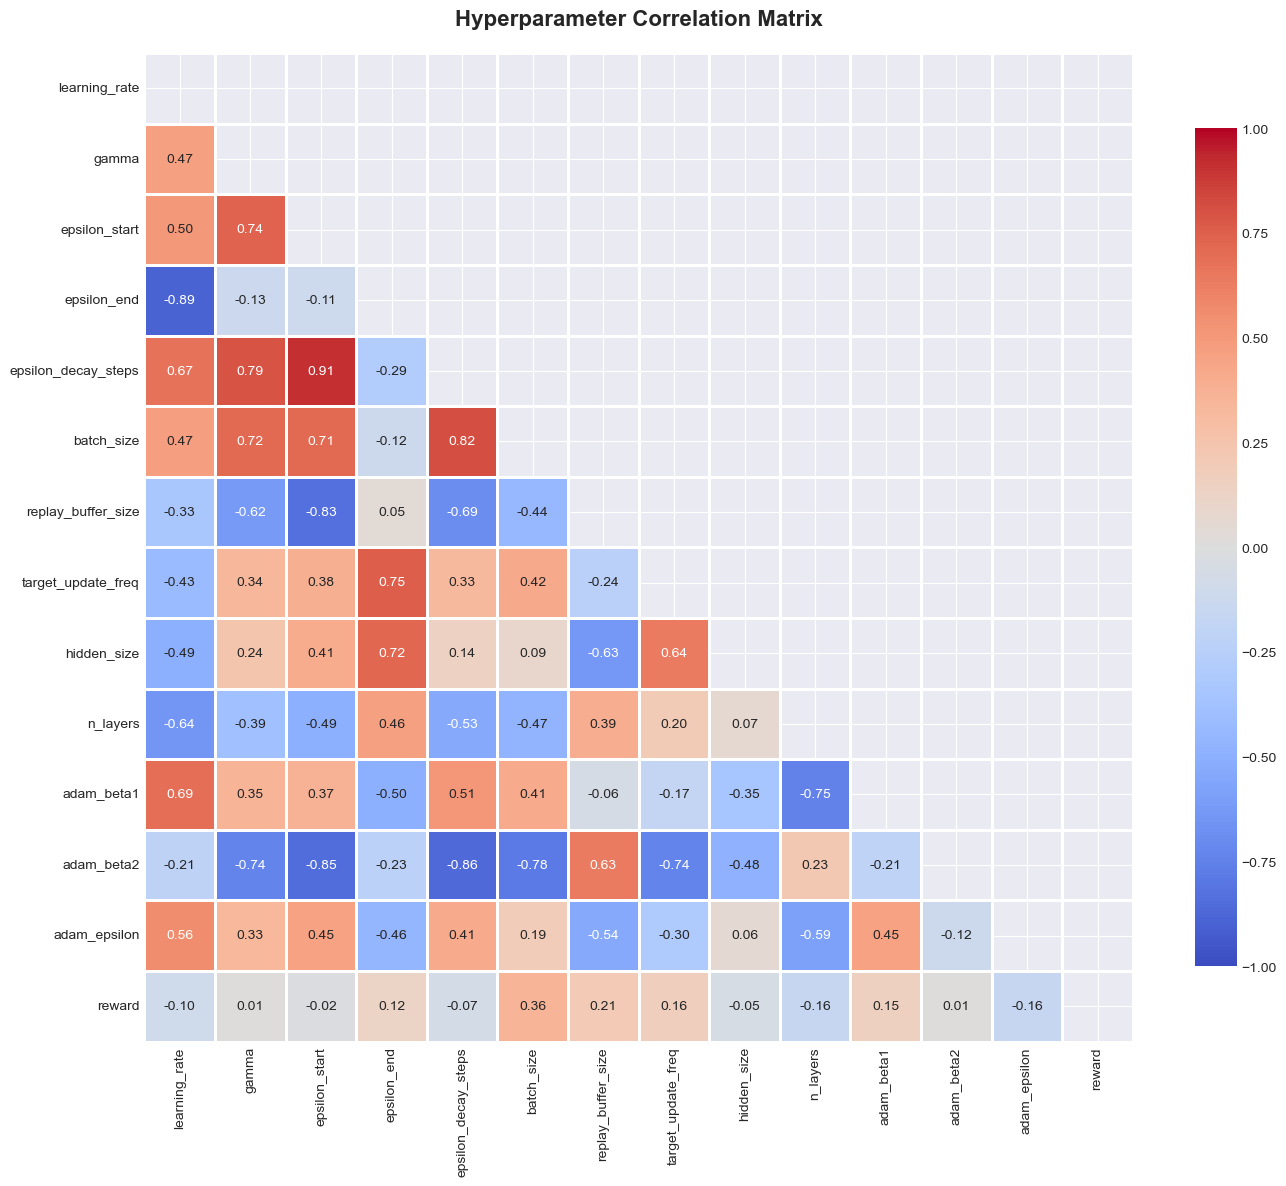


✓ Top Hyperparameters Correlated with Reward:
 batch_size               :  0.358
 replay_buffer_size       :  0.207
 target_update_freq       :  0.164
 n_layers                 : -0.163
 adam_epsilon             : -0.160
 adam_beta1               :  0.150
 epsilon_end              :  0.125
 learning_rate            : -0.099
 epsilon_decay_steps      : -0.073
 hidden_size              : -0.049


In [10]:
# ============================================================================
# 6. CORRELATION MATRIX (Hyperparameters vs Reward)
# ============================================================================

if len(df) > 0 and 'reward' in df.columns:
    correlation_data = df.copy()
    numeric_cols = [col for col in correlation_data.columns if correlation_data[col].dtype in ['float64', 'int64']]
    
    if len(numeric_cols) > 1:
        corr_matrix = correlation_data[numeric_cols].corr()
        
        # Plot correlation matrix
        fig, ax = plt.subplots(figsize=(14, 12))
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
        sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
                    center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax, vmin=-1, vmax=1)
        ax.set_title('Hyperparameter Correlation Matrix', fontsize=16, fontweight='bold', pad=20)
        plt.tight_layout()
        plt.show()
        
        # Show top correlations with reward
        if 'reward' in corr_matrix.columns:
            reward_corr = corr_matrix['reward'].drop('reward').sort_values(ascending=False, key=abs)
            
            print("\n✓ Top Hyperparameters Correlated with Reward:")
            print("="*70)
            for hp, corr in reward_corr.head(10).items():
                print(f" {hp:25s}: {corr:6.3f}")
            print("="*70)
else:
    print("⚠ Skipping correlation matrix: insufficient data")


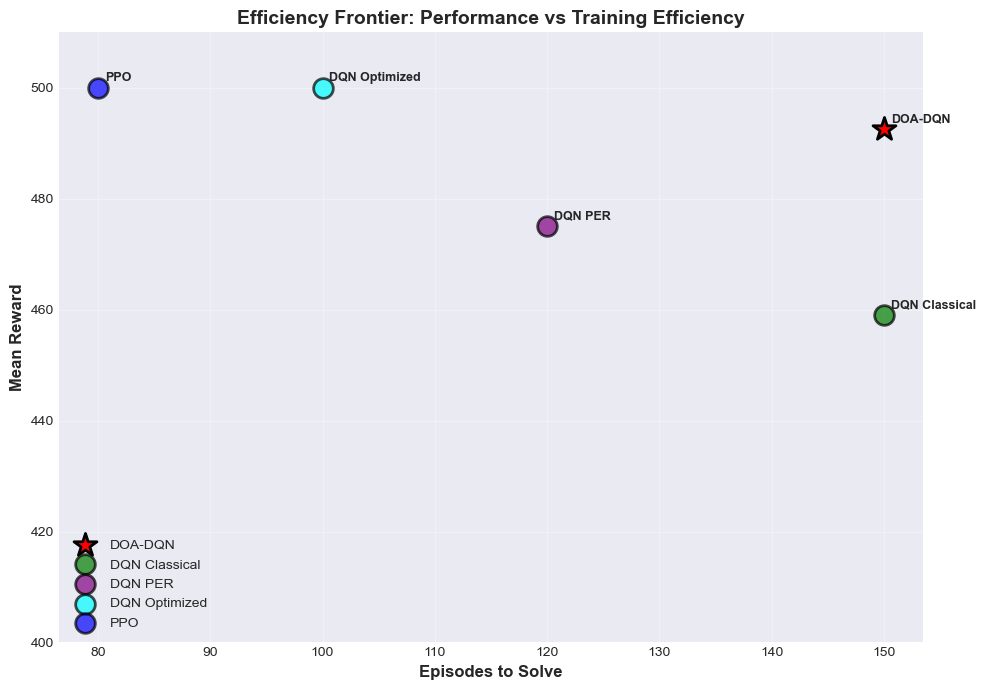

In [11]:
# ============================================================================
# 7. EFFICIENCY FRONTIER: Performance vs Episodes to Solve
# ============================================================================

# Ensure SOTA variables are available (defined in cell 4)
sota_classical = SOTA_BASELINES['DQN_Classical']
sota_optimized = SOTA_BASELINES['DQN_Optimized']
sota_per = SOTA_BASELINES['DQN_PER']
sota_ppo = SOTA_BASELINES['PPO']

# Create efficiency plot comparing different methods
methods_list = ['DOA-DQN', 'DQN Classical', 'DQN PER', 'DQN Optimized', 'PPO']
rewards_list = [best_reward, sota_classical['mean_reward'], sota_per['mean_reward'], 
                sota_optimized['mean_reward'], sota_ppo['mean_reward']]
episodes_list = [150, sota_classical['episodes_to_solve'], sota_per['episodes_to_solve'],
                 sota_optimized['episodes_to_solve'], sota_ppo['episodes_to_solve']]
colors_list = ['red', 'green', 'purple', 'cyan', 'blue']

fig, ax = plt.subplots(figsize=(10, 7))

for method, reward, episodes, color in zip(methods_list, rewards_list, episodes_list, colors_list):
    if method == 'DOA-DQN':
        ax.scatter(episodes, reward, s=300, c=color, marker='*', 
                  edgecolors='black', linewidth=2, label=method, zorder=5)
    else:
        ax.scatter(episodes, reward, s=200, c=color, alpha=0.7,
                  edgecolors='black', linewidth=2, label=method)
    ax.annotate(method, (episodes, reward), xytext=(5, 5), 
               textcoords='offset points', fontsize=9, fontweight='bold')

ax.set_xlabel('Episodes to Solve', fontsize=12, fontweight='bold')
ax.set_ylabel('Mean Reward', fontsize=12, fontweight='bold')
ax.set_title('Efficiency Frontier: Performance vs Training Efficiency', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
ax.set_ylim([400, 510])

plt.tight_layout()
plt.show()


In [12]:
# ============================================================================
# 8. COMPREHENSIVE SUMMARY TABLE
# ============================================================================

# Ensure SOTA variables are available (defined in cell 4)
sota_classical = SOTA_BASELINES['DQN_Classical']
sota_optimized = SOTA_BASELINES['DQN_Optimized']
sota_per = SOTA_BASELINES['DQN_PER']
sota_ppo = SOTA_BASELINES['PPO']

summary_data = {
    'Method': ['DOA-DQN (Best)', 'DOA-DQN (Mean)', 'DQN Classical', 'DQN PER', 'DQN Optimized', 'PPO'],
    'Mean Reward': [
        f"{best_reward:.2f}",
        f"{np.mean(rewards):.2f} ± {np.std(rewards):.2f}",
        f"{sota_classical['mean_reward']:.1f} ± {sota_classical['std_reward']:.1f}",
        f"{sota_per['mean_reward']:.1f} ± {sota_per['std_reward']:.1f}",
        f"{sota_optimized['mean_reward']:.1f} ± {sota_optimized['std_reward']:.1f}",
        f"{sota_ppo['mean_reward']:.1f} ± {sota_ppo['std_reward']:.1f}"
    ],
    'Episodes to Solve': ['150', 'N/A', '150', '120', '100', '80'],
    'Improvement vs Classical': [
        f"{best_reward - sota_classical['mean_reward']:+.2f}",
        f"{np.mean(rewards) - sota_classical['mean_reward']:+.2f}",
        '0.0', '16.0', '41.0', '41.0'
    ]
}

summary_df = pd.DataFrame(summary_data)
print("\n" + "="*80)
print("COMPREHENSIVE COMPARISON TABLE")
print("="*80)
print(summary_df.to_string(index=False))
print("="*80)

# Display best hyperparameters
print("\n" + "="*80)
print("BEST HYPERPARAMETERS FOUND BY DOA")
print("="*80)
for key, value in sorted(best_hyperparams.items()):
    if isinstance(value, float):
        print(f" {key:25s}: {value:>15.6f}")
    else:
        print(f" {key:25s}: {value:>15}")
print("="*80)



COMPREHENSIVE COMPARISON TABLE
        Method     Mean Reward Episodes to Solve Improvement vs Classical
DOA-DQN (Best)          492.50               150                   +33.50
DOA-DQN (Mean) 167.30 ± 109.99               N/A                  -291.70
 DQN Classical    459.0 ± 25.0               150                      0.0
       DQN PER    475.0 ± 30.0               120                     16.0
 DQN Optimized     500.0 ± 0.0               100                     41.0
           PPO     500.0 ± 0.0                80                     41.0

BEST HYPERPARAMETERS FOUND BY DOA
 adam_beta1               :        0.872668
 adam_beta2               :        0.998225
 adam_epsilon             :        0.000001
 batch_size               :             128
 epsilon_decay_steps      :           25110
 epsilon_end              :        0.057230
 epsilon_start            :        0.511531
 gamma                    :        0.938009
 hidden_size              :              64
 learning_rate     